# 01 - EDA: Concrete Compressive Strength
Goal: understand the data before modeling. 

In [30]:
import pandas as pd
import numpy as np

RAW_PATH = "../data/raw/concrete.csv"
df_raw = pd.read_csv(RAW_PATH)
df_raw.shape

(1030, 9)

In [31]:
COLS = [
    "cement", "slag", "fly_ash", "water", "superplasticizer",
    "coarse_agg", "fine_agg", "age_days", "strength_mpa",
]
assert len(COLS) == df_raw.shape[1], "column count mismatch"
df = df_raw.copy()
df.columns = COLS
df.sample(5)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_mpa
13,190.0,190.0,0.00,228.00,0.00,932.00,670.00,90,42.326932
250,250.0,0.0,95.69,187.42,5.53,956.86,861.17,14,24.917663
999,150.9,0.0,183.90,166.60,11.60,991.20,772.20,28,15.569747
475,446.0,24.0,79.00,162.00,11.61,967.00,712.00,3,35.363224
745,281.0,0.0,0.00,185.00,0.00,1104.00,774.00,28,22.435549


In [32]:
# Sanity checks: types, missing values, duplicates
print(df.dtypes, "\n")
print("missing per column:\n", df.isnull().sum(), "\n")
print("duplicate rows:", df.duplicated().sum())

cement              float64
slag                float64
fly_ash             float64
water               float64
superplasticizer    float64
coarse_agg          float64
fine_agg            float64
age_days              int64
strength_mpa        float64
dtype: object 

missing per column:
 cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age_days            0
strength_mpa        0
dtype: int64 

duplicate rows: 25


- **Finding:** 25 exact duplicate rows.
- **Decision:** remove them (keep first) before any train/test split, so identical rows cannot leak into the test set. The dedupe below is in-memory only, so the rest of EDA is not skewed by repeats. The permanent cleaning will live in `src/features.py`.

In [33]:
# Look before deleting: keep=False shows EVERY copy (original + twins)
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print(len(dups), "rows involved in duplication")
dups.head(10)

36 rows involved in duplication


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_mpa
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [34]:
n_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(n_before, "->", len(df), "| removed:", n_before - len(df))
assert df.duplicated().sum() == 0

1030 -> 1005 | removed: 25


## Step 2 - Summary statistics and distributions
Goal: check that value ranges make physical sense and see the shape of each variable.

In [35]:
# count, mean, std, min, quartiles, max per column (.T puts features in rows)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
slag,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
fly_ash,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
water,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplasticizer,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
coarse_agg,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
fine_agg,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
age_days,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
strength_mpa,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


In [36]:
# A 0 here means 'ingredient not used in this mix', NOT missing data
print("% of rows equal to 0:")
print((df == 0).mean().mul(100).round(1))

% of rows equal to 0:
cement               0.0
slag                46.3
fly_ash             53.8
water                0.0
superplasticizer    37.6
coarse_agg           0.0
fine_agg             0.0
age_days             0.0
strength_mpa         0.0
dtype: float64


- **Findings**:
    - `compulsory ingredients`: cement,water,coarse_agg,fine_agg
    - `optional ingredients`: slag,fly_ash,superplasticizer

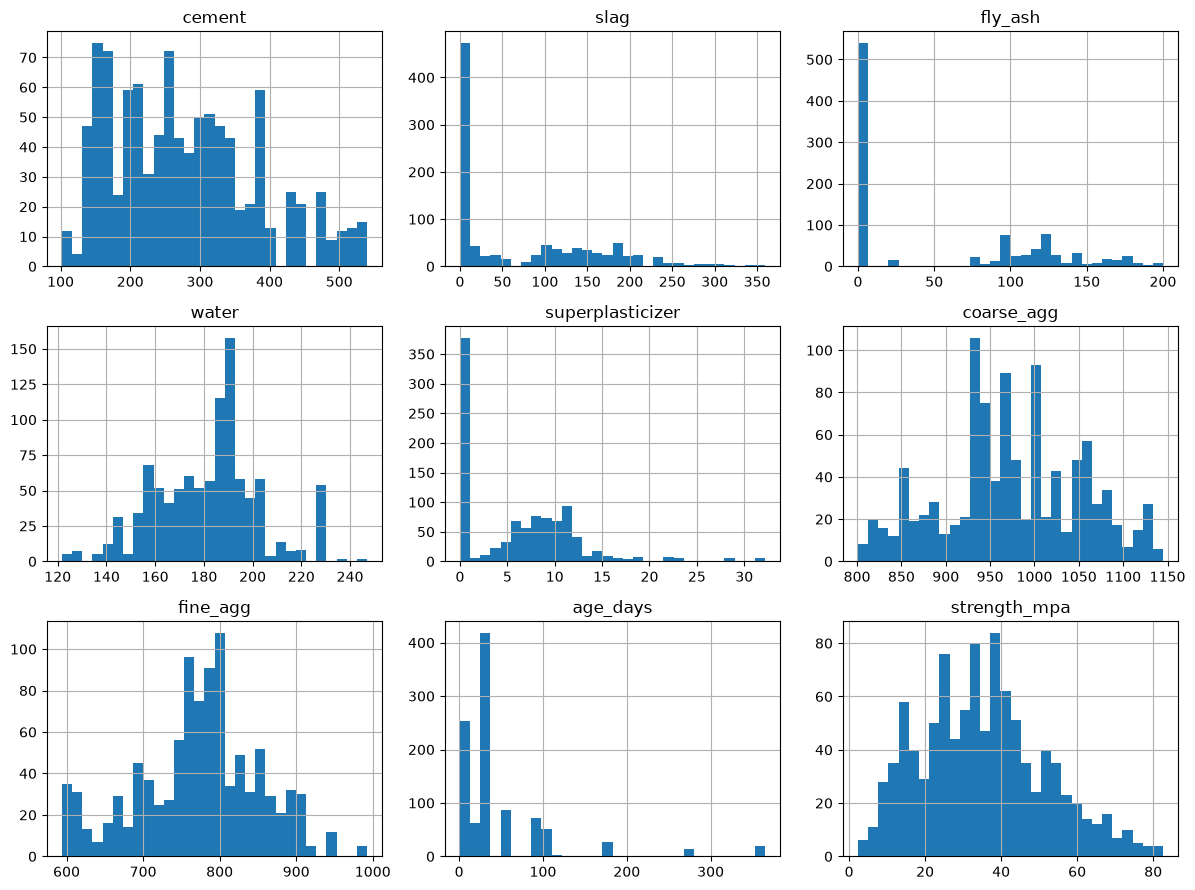

In [37]:
import matplotlib.pyplot as plt

df.hist(bins=30, figsize=(12, 9))
plt.tight_layout()
plt.show()

In [38]:
df["age_days"].value_counts().sort_index()

age_days
1        2
3      129
7      122
14      62
28     419
56      86
90      54
91      17
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64

- **Findings**: 
    - Age is very uneven. Day 28 is 419 of 1005 rows (42%), days 3 and 7 together are 251 (25%), and ages ≥ 90 days are only 185 rows (18%) spread over 8 values (day 1 has 2 rows).
    - Days 90 and 91 are essentially the same test age, probably from different sources. We may group them later.
    - Day 28 dominates because 28 days is the standard age at which concrete strength is specified and tested.